# Peta spasial eval2

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Bobot mengikuti `eval2.do`: queen dari daftar sisi, W pulau leave-one-out di dalam pulau.
--> Moran pada rata-rata provinsi.
--> Angka I pada batang = korelasi y dengan Wy yang disimpan eval2.
--> Scatter queen: I = z′Wz / z′z.
--> Gambar: `01 Data/TFP/output/eval/viz2/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C",
)
PULAU_ORDER = ["Sumatera", "Jawa", "Bali-Nusra", "Kalimantan", "Sulawesi", "Maluku-Papua"]
PULAU_FILL = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PULAU_INK = {
    "Sumatera": "#8A6A32", "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PILAR_COLOR = {
    "pendidikan": NAVY, "equity": TEAL, "institusi": "#062E4C",
    "konektivitas": CYAN, "lingkungan": "#30726A", "keamanan": GRAY,
}
LISA_COLOR = {"HH": NAVY, "HL": CYAN, "LH": CREAM, "LL": RED}
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
PULAU_OF = {}
for code, pulau in {
    **{c: "Sumatera" for c in [11, 12, 13, 14, 15, 16, 17, 18, 19, 21]},
    **{c: "Jawa" for c in [31, 32, 33, 34, 35, 36]},
    **{c: "Bali-Nusra" for c in [51, 52, 53]},
    **{c: "Kalimantan" for c in [61, 62, 63, 64, 65]},
    **{c: "Sulawesi" for c in [71, 72, 73, 74, 75, 76]},
    **{c: "Maluku-Papua" for c in [81, 82, 91, 94]},
}.items():
    PULAU_OF[code] = pulau
NAME2CODE = {
    "Aceh": 11, "SumateraUtara": 12, "SumateraBarat": 13, "Riau": 14,
    "Jambi": 15, "SumateraSelatan": 16, "Bengkulu": 17, "Lampung": 18,
    "BangkaBelitung": 19, "KepulauanRiau": 21, "JakartaRaya": 31,
    "JawaBarat": 32, "JawaTengah": 33, "Yogyakarta": 34, "JawaTimur": 35,
    "Banten": 36, "Bali": 51, "NusaTenggaraBarat": 52, "NusaTenggaraTimur": 53,
    "KalimantanBarat": 61, "KalimantanTengah": 62, "KalimantanSelatan": 63,
    "KalimantanTimur": 64, "KalimantanUtara": 65, "SulawesiUtara": 71,
    "SulawesiTengah": 72, "SulawesiSelatan": 73, "SulawesiTenggara": 74,
    "Gorontalo": 75, "SulawesiBarat": 76, "Maluku": 81, "MalukuUtara": 82,
    "PapuaBarat": 91, "Papua": 94,
}
# Sisi tak-berarah, daftar eval2.do.
QUEEN_PAIRS = [
    (11, 12), (12, 13), (13, 14), (13, 15), (13, 16), (14, 15), (14, 16), (14, 21),
    (15, 16), (15, 17), (16, 17), (16, 18), (16, 19), (17, 18),
    (31, 32), (31, 36), (32, 33), (32, 36), (33, 34), (33, 35), (35, 51),
    (51, 52), (52, 53),
    (61, 62), (61, 63), (62, 63), (62, 64), (63, 64), (64, 65),
    (71, 72), (71, 75), (71, 82), (72, 73), (72, 74), (72, 75), (72, 76), (73, 74), (73, 76),
    (81, 82), (81, 94), (91, 94),
]
ARCHI_PAIRS = {(14, 21), (16, 19)}  # se-pulau, tetapi dipisah laut
LAB = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_ln_lama_sekolah_harapan": "harapan sekolah",
    "z_db_sd": "−APK SD", "z_db_smp": "−APK SMP", "z_db_sma": "−APK SMA", "z_db_kampus": "−APK kampus",
    "z_ln_p1": "−kedalaman miskin", "z_ln_ipm": "IPM", "z_gini": "Gini",
    "z_ln_upah_rata": "upah rata-rata", "z_ln_indeks_demokrasi": "IDI",
    "z_price": "−deflator", "z_ln_rasio_pad": "rasio PAD",
    "z_ln_pertumbuhan_pdrb_adhb": "pertumbuhan ADHB", "z_ln_apbd_belanja": "belanja APBD",
    "z_ln_jalan_mantap": "jalan mantap", "z_ln_kargo_udara": "kargo udara",
    "z_ln_kargo_kapal": "kargo kapal", "z_ln_kargo_kereta": "kargo kereta",
    "z_ln_penumpang_total": "penumpang", "z_ln_airport_logistik": "bandara logistik",
    "z_ln_airport_komersil": "bandara komersial",
    "z_ln_indeks_lingkungan": "IKLH", "z_ln_indeks_hijau": "indeks hijau", "z_ln_indeks_biru": "indeks biru",
    "z_ln_crime_risk": "−risiko kriminal", "z_ln_crime_rate": "−crime rate",
    "z_ln_apbd_serapan": "serapan",
    "Wq_pilar_pendidikan": "Wq pendidikan", "Wq_pilar_equity": "Wq equity",
    "Wq_pilar_institusi": "Wq institusi", "Wq_rasio_pad": "Wq rasio PAD",
    "Wq_ln_apbd_belanja": "Wq belanja", "Wi_rasio_pad": "Wi rasio PAD",
    "share_inv_padat_karya": "inv. padat karya", "share_inv_padat_modal": "inv. padat modal",
    "share_inv_primer": "inv. primer", "share_inv_sekunder": "inv. sekunder",
    "share_inv_C": "inv. industri", "share_tk_C": "TK industri",
    "d_dom_primer": "dominan primer", "d_dom_sekunder": "dominan sekunder",
    "share_inv_hijau_inv": "inv. hijau", "share_tk_ekstraktif": "TK ekstraktif",
    "share_inv_A": "inv. pertanian", "d_sawit": "sawit (p75)", "kantong_lemah": "kantong lemah",
}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "medium", "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def save(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    print(path.relative_to(ROOT))
    plt.show()

def star(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

def row_std(A):
    A = np.asarray(A, float)
    s = A.sum(1, keepdims=True)
    s[s == 0] = 1.0
    return A / s

def moran_I(y, W):
    z = np.asarray(y, float)
    z = z - np.nanmean(z)
    den = float(z @ z)
    if den <= 0:
        return np.nan
    return float(z @ (W @ z) / den)

def moran_p(y, W, nperm=999, seed=11):
    rng = np.random.default_rng(seed)
    y = np.asarray(y, float)
    I0 = moran_I(y, W)
    hits = 0
    for _ in range(nperm):
        if abs(moran_I(rng.permutation(y), W)) >= abs(I0) - 1e-15:
            hits += 1
    return I0, (hits + 1) / (nperm + 1)

def edge_style(a, b):
    pair = tuple(sorted((int(a), int(b))))
    if PULAU_OF[pair[0]] != PULAU_OF[pair[1]]:
        return RED, "-"
    if pair in ARCHI_PAIRS:
        return "#8A6A32", "--"
    return NAVY, "-"

def ordered_codes():
    return [c for p in PULAU_ORDER for c in SHORT if PULAU_OF[c] == p]

def weights(codes):
    n = len(codes)
    idx = {c: i for i, c in enumerate(codes)}
    A = np.zeros((n, n))
    for a, b in QUEEN_PAIRS:
        i, j = idx[a], idx[b]
        A[i, j] = A[j, i] = 1.0
    Ai = np.zeros((n, n))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            if i != j and PULAU_OF[ci] == PULAU_OF[cj]:
                Ai[i, j] = 1.0
    return A, Ai, row_std(A), row_std(Ai)

def load_gdf(codes):
    import geopandas as gpd
    gadm = ROOT / "02 Code" / "TFP" / "docs" / "06 Review" / "assets" / "gadm41_IDN_1.json"
    g = gpd.read_file(gadm)[["NAME_1", "geometry"]]
    g["Code_Prov"] = g["NAME_1"].map(NAME2CODE)
    g = g.dropna(subset=["Code_Prov"])
    g["Code_Prov"] = g["Code_Prov"].astype(int)
    g = g.dissolve(by="Code_Prov", as_index=False)
    g = g.set_index("Code_Prov").reindex(codes).reset_index()
    if g["geometry"].isna().any():
        raise RuntimeError("GADM tidak memuat semua kode provinsi 34")
    g = g.to_crs(3857)
    g["geometry"] = g.geometry.simplify(2000, preserve_topology=True)
    g["Pulau"] = g["Code_Prov"].map(PULAU_OF)
    g["short"] = g["Code_Prov"].map(SHORT)
    return g

def choro(ax, gdf, col, title, center="zero"):
    s = gdf[col].astype(float)
    if center == "zero":
        v = np.nanmax(np.abs(s.to_numpy()))
        v = 1e-6 if not np.isfinite(v) or v == 0 else float(v)
        norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-v, vmax=v)
        cmap = "RdBu_r"
    elif center == "mean":
        mu = float(np.nanmean(s))
        v = max(mu - float(np.nanmin(s)), float(np.nanmax(s)) - mu, 1e-6)
        norm = mcolors.TwoSlopeNorm(vcenter=mu, vmin=mu - v, vmax=mu + v)
        cmap = "RdBu_r"
    else:
        norm = mcolors.Normalize(vmin=float(np.nanmin(s)), vmax=float(np.nanmax(s)))
        cmap = "PuBu"
    gdf.plot(column=col, ax=ax, cmap=cmap, norm=norm, linewidth=0.3,
             edgecolor="white", missing_kwds={"color": "#eeeeee"})
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cb = ax.figure.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
    cb.ax.tick_params(labelsize=7)
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    ax.set_facecolor("#f6f5f2")

def style_map(ax):
    ax.set_axis_off()
    ax.set_facecolor("#f6f5f2")
    ax.grid(False)

def lisa_labels(y, wy):
    my, mw = np.median(y), np.median(wy)
    out = np.empty(len(y), dtype=object)
    for i, (a, b) in enumerate(zip(y, wy)):
        if a >= my and b >= mw:
            out[i] = "HH"
        elif a < my and b < mw:
            out[i] = "LL"
        elif a >= my and b < mw:
            out[i] = "HL"
        else:
            out[i] = "LH"
    return out

def draw_queen(ax, gdf, title):
    gdf.plot(ax=ax, color="#f4f1ea", edgecolor="white", linewidth=0.45)
    pts = gdf.set_index("Code_Prov").geometry.representative_point()
    for a, b in QUEEN_PAIRS:
        color, ls = edge_style(a, b)
        ax.plot([pts[a].x, pts[b].x], [pts[a].y, pts[b].y],
                color=color, ls=ls, lw=1.15, zorder=3, solid_capstyle="round")
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[
        Line2D([0], [0], color=NAVY, lw=1.4, label="queen, darat"),
        Line2D([0], [0], color="#8A6A32", lw=1.4, ls="--", label="queen, laut se-pulau"),
        Line2D([0], [0], color=RED, lw=1.4, label="queen, antar-pulau"),
    ], loc="lower left", fontsize=8)

def draw_islands(ax, gdf, title):
    for p in PULAU_ORDER:
        gdf[gdf.Pulau == p].plot(ax=ax, color=PULAU_FILL[p], edgecolor="white", linewidth=0.45)
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=PULAU_FILL[p], edgecolor=GRAY, label=p) for p in PULAU_ORDER],
              loc="lower left", fontsize=8)

def block_lines(ax, codes):
    cuts = []
    start = 0
    for p in PULAU_ORDER:
        k = sum(PULAU_OF[c] == p for c in codes)
        cuts.append(start + k)
        start += k
    for c in cuts[:-1]:
        ax.axhline(c - 0.5, color=RED, lw=0.6)
        ax.axvline(c - 0.5, color=RED, lw=0.6)

OUT = ROOT / "01 Data" / "TFP" / "output" / "eval" / "viz2"
OUT.mkdir(parents=True, exist_ok=True)
bt = pd.read_csv(ROOT / "01 Data" / "TFP" / "output" / "eval" / "eval2_between.csv")
bt["Code_Prov"] = bt["Code_Prov"].astype(int)
bt["Pulau"] = bt["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
mor = pd.read_csv(ROOT / "01 Data" / "TFP" / "output" / "eval" / "eval2_moran.csv")
mor["var"] = mor["var"].replace({"pilar_konektivit": "pilar_konektivitas"})
coef = pd.read_csv(ROOT / "01 Data" / "TFP" / "output" / "eval" / "eval2_coef.csv")
codes = ordered_codes()
A, Ai, Wq, Wi = weights(codes)
gdf = load_gdf(codes)
bt = bt.set_index("Code_Prov").loc[codes].reset_index()
y = bt["logtfp_it_crs"].to_numpy()
lag = Wq @ y
stored = bt["Wq_logtfp_it_crs"].to_numpy()
fit = np.corrcoef(lag, stored)[0, 1]
if fit < 0.99:
    raise RuntimeError(f"W queen tidak sama dengan eval2 (korelasi lag = {fit:.3f})")
print(f"W queen cocok dengan eval2 (korelasi lag CRS = {fit:.3f})")


W queen cocok dengan eval2 (korelasi lag CRS = 1.000)


## Kontiguitas yang dipakai regresi


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/eval/viz2/ev2_matriks_W.png
01 Data/TFP/output/eval/viz2/ev2_peta_kontiguitas.png


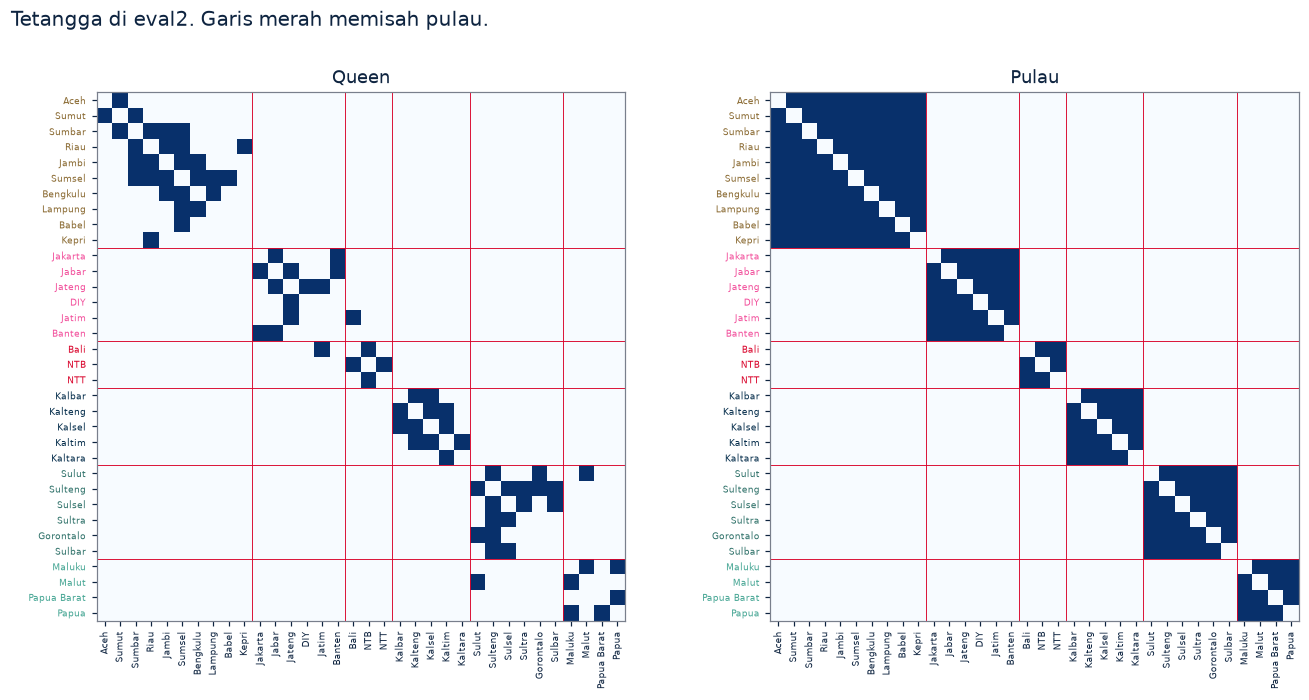

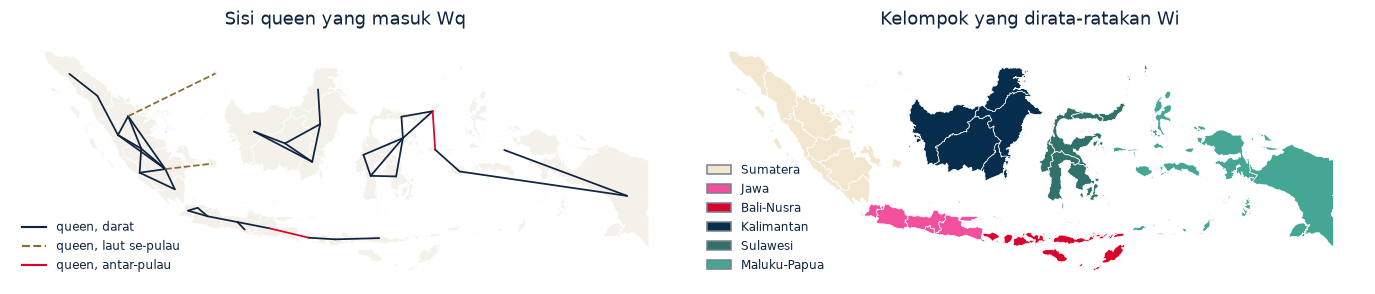

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 6.2))
shorts = [SHORT[c] for c in codes]
for ax, M, title in zip(axes, [A, Ai], ["Queen", "Pulau"]):
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1, origin="upper")
    ax.set_xticks(range(len(codes)))
    ax.set_yticks(range(len(codes)))
    ax.set_xticklabels(shorts, rotation=90, fontsize=6)
    ax.set_yticklabels(shorts, fontsize=6)
    for tick, c in zip(ax.get_yticklabels(), codes):
        tick.set_color(PULAU_INK[PULAU_OF[c]])
    block_lines(ax, codes)
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Tetangga di eval2. Garis merah memisah pulau.", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, "ev2_matriks_W.png")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 6.8))
draw_queen(axes[0], gdf, "Sisi queen yang masuk Wq")
draw_islands(axes[1], gdf, "Kelompok yang dirata-ratakan Wi")
fig.tight_layout()
save(fig, "ev2_peta_kontiguitas.png")


## Moran, level, kuadran, kantong


01 Data/TFP/output/eval/viz2/ev2_moran_batang.png
01 Data/TFP/output/eval/viz2/ev2_moran_scatter.png
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/eval/viz2/ev2_peta_level.png
01 Data/TFP/output/eval/viz2/ev2_lisa.png
01 Data/TFP/output/eval/viz2/ev2_kantong.png


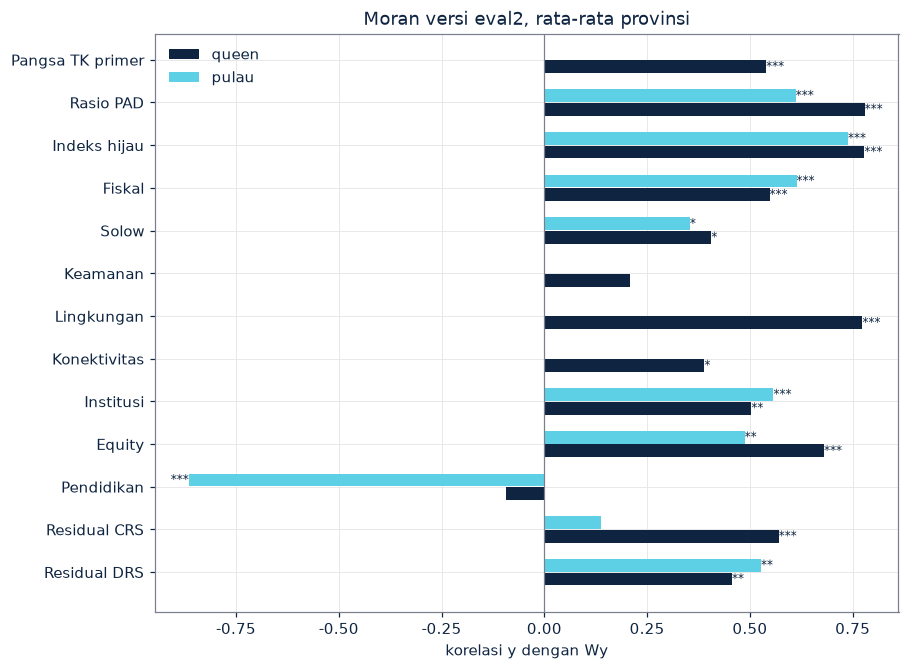

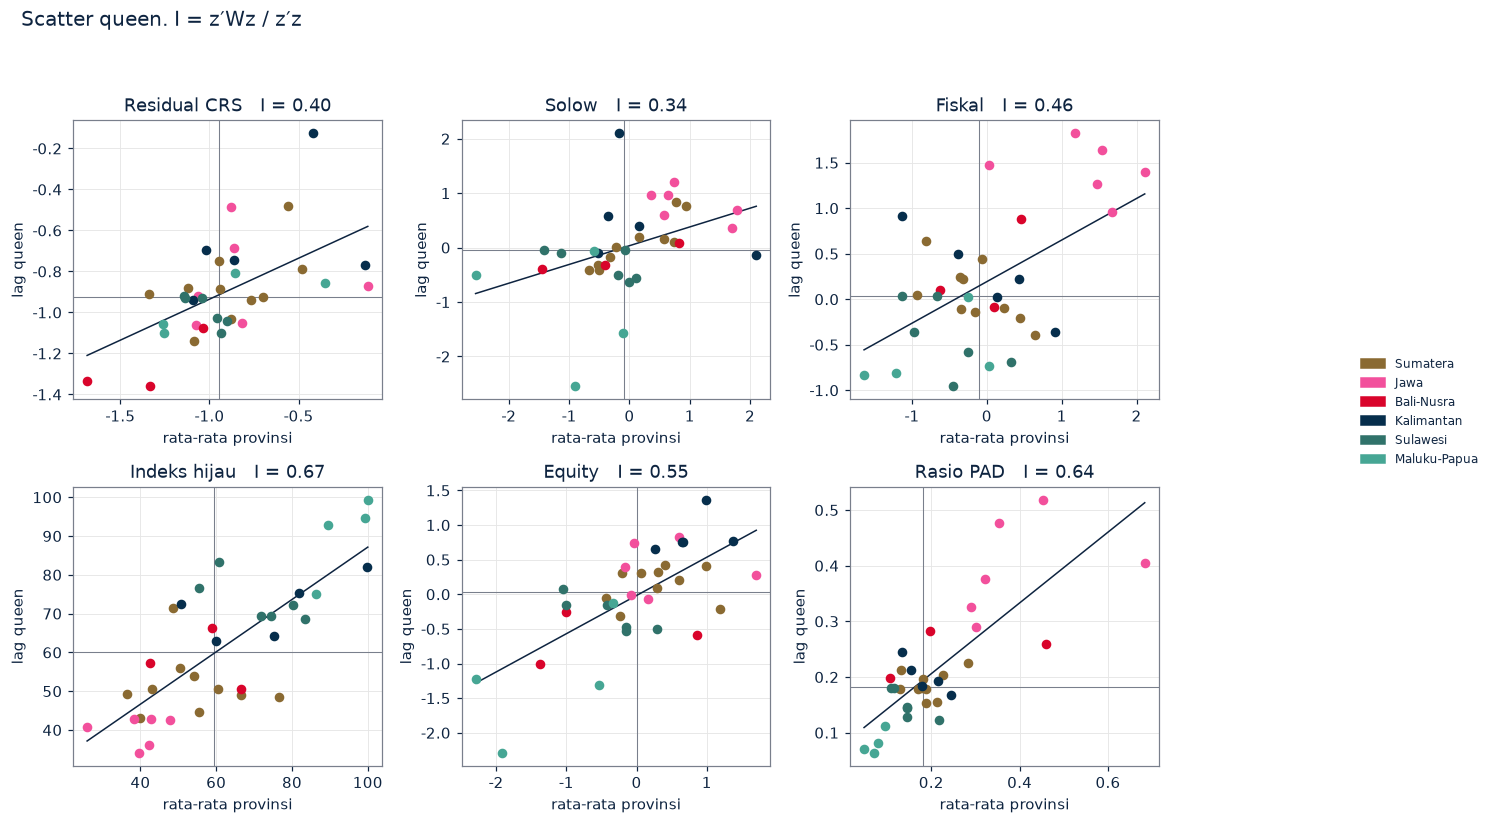

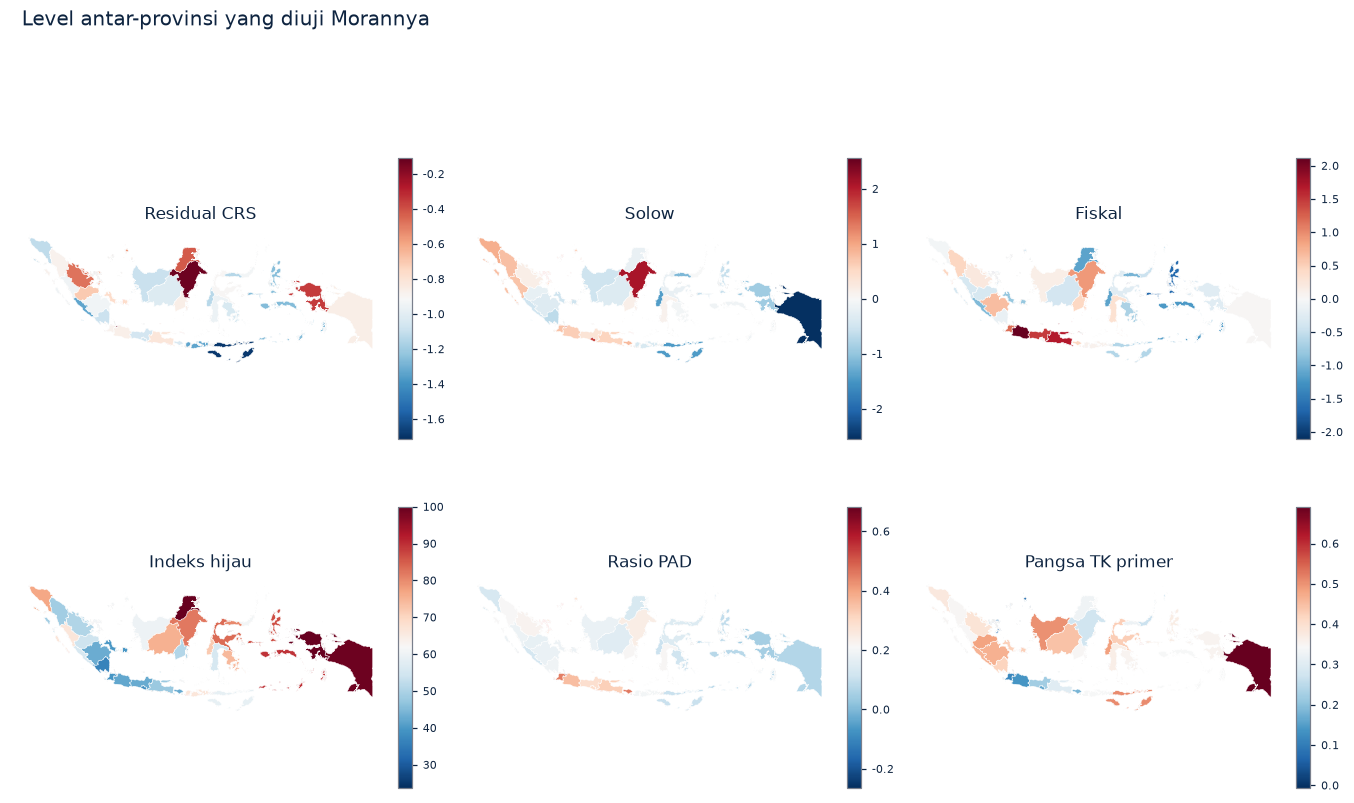

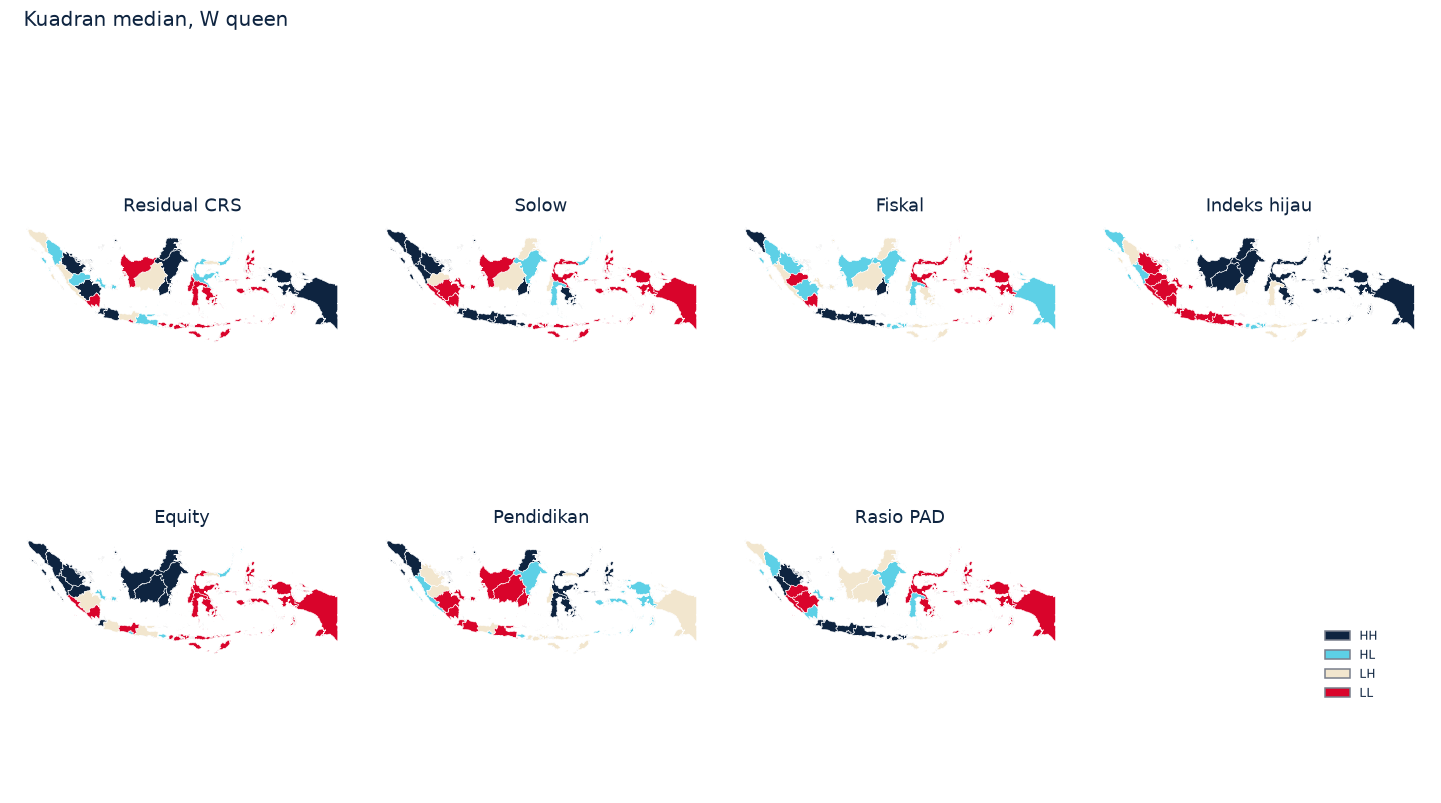

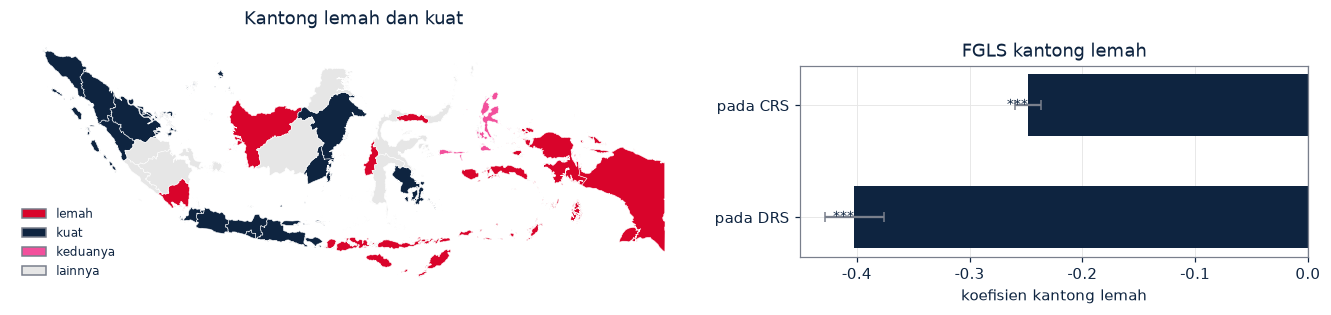

In [3]:
nice = {
    "logtfp_it": "Residual DRS", "logtfp_it_crs": "Residual CRS",
    "pilar_pendidikan": "Pendidikan", "pilar_equity": "Equity",
    "pilar_institusi": "Institusi", "pilar_konektivitas": "Konektivitas",
    "pilar_lingkungan": "Lingkungan", "pilar_keamanan": "Keamanan",
    "idx_solow": "Solow", "idx_fiskal": "Fiskal",
    "indeks_hijau": "Indeks hijau", "rasio_pad": "Rasio PAD",
    "share_tk_primer": "Pangsa TK primer",
}
order_vars = [v for v in nice if v in set(mor["var"])]
fig, ax = plt.subplots(figsize=(8.4, 6.2))
ypos = np.arange(len(order_vars))
for shift, wname, color in [(-0.16, "Wq", NAVY), (0.16, "Wi", CYAN)]:
    sub = mor[mor.W == wname].drop_duplicates("var").set_index("var")
    vals = [sub.loc[v, "I"] if v in sub.index else np.nan for v in order_vars]
    ps = [sub.loc[v, "p"] if v in sub.index else np.nan for v in order_vars]
    ax.barh(ypos + shift, vals, height=0.3, color=color, label={"Wq": "queen", "Wi": "pulau"}[wname])
    for yi, (I, p) in zip(ypos + shift, zip(vals, ps)):
        if pd.notna(p) and star(p):
            ax.text(I, yi, star(p), va="center", ha="left" if I >= 0 else "right", fontsize=8)
ax.set_yticks(ypos)
ax.set_yticklabels([nice[v] for v in order_vars])
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("korelasi y dengan Wy")
ax.set_title("Moran versi eval2, rata-rata provinsi")
ax.legend()
fig.tight_layout()
save(fig, "ev2_moran_batang.png")

scatter_spec = [
    ("logtfp_it_crs", "Wq_logtfp_it_crs", "Residual CRS"),
    ("idx_solow", "Wq_idx_solow", "Solow"),
    ("idx_fiskal", "Wq_idx_fiskal", "Fiskal"),
    ("indeks_hijau", "Wq_indeks_hijau", "Indeks hijau"),
    ("pilar_equity", "Wq_pilar_equity", "Equity"),
    ("rasio_pad", "Wq_rasio_pad", "Rasio PAD"),
]
fig, axes = plt.subplots(2, 3, figsize=(12.2, 7.6))
for ax, (ycol, wcol, title) in zip(axes.ravel(), scatter_spec):
    yv = bt[ycol].to_numpy()
    wv = bt[wcol].to_numpy()
    for p in PULAU_ORDER:
        m = bt["Pulau"].to_numpy() == p
        ax.scatter(yv[m], wv[m], s=28, color=PULAU_INK[p], label=p, zorder=3)
    ax.axvline(np.median(yv), color=GRAY, lw=0.7)
    ax.axhline(np.median(wv), color=GRAY, lw=0.7)
    b1, b0 = np.polyfit(yv, wv, 1)
    xs = np.linspace(yv.min(), yv.max(), 40)
    ax.plot(xs, b0 + b1 * xs, color=NAVY, lw=1)
    I = moran_I(yv, Wq)
    ax.set_title(f"{title}   I = {I:.2f}")
    ax.set_xlabel("rata-rata provinsi")
    ax.set_ylabel("lag queen")
fig.legend(handles=[Patch(color=PULAU_INK[p], label=p) for p in PULAU_ORDER],
           loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle("Scatter queen. I = z′Wz / z′z", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 0.88, 0.94))
save(fig, "ev2_moran_scatter.png")

level_spec = [
    ("logtfp_it_crs", "Residual CRS", "mean"),
    ("idx_solow", "Solow", "zero"),
    ("idx_fiskal", "Fiskal", "zero"),
    ("indeks_hijau", "Indeks hijau", "mean"),
    ("rasio_pad", "Rasio PAD", "mean"),
    ("share_tk_primer", "Pangsa TK primer", "mean"),
]
for col, _, _ in level_spec:
    gdf[col] = gdf["Code_Prov"].map(bt.set_index("Code_Prov")[col])
fig, axes = plt.subplots(2, 3, figsize=(12.4, 8.0))
for ax, (col, title, center) in zip(axes.ravel(), level_spec):
    choro(ax, gdf, col, title, center=center)
fig.suptitle("Level antar-provinsi yang diuji Morannya", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev2_peta_level.png")

lisa_cols = [
    ("lisa_logtfp_it_crs", "Residual CRS"),
    ("lisa_idx_solow", "Solow"),
    ("lisa_idx_fiskal", "Fiskal"),
    ("lisa_indeks_hijau", "Indeks hijau"),
    ("lisa_pilar_equity", "Equity"),
    ("lisa_pilar_pendidikan", "Pendidikan"),
    ("lisa_rasio_pad", "Rasio PAD"),
]
fig, axes = plt.subplots(2, 4, figsize=(13.2, 7.4))
for ax, (col, title) in zip(axes.ravel(), lisa_cols):
    gg = gdf.copy()
    gg["lisa"] = gg["Code_Prov"].map(bt.set_index("Code_Prov")[col])
    for lab, color in LISA_COLOR.items():
        sub = gg[gg.lisa == lab]
        if len(sub):
            sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.35)
    style_map(ax)
    ax.set_title(title)
axes.ravel()[-1].axis("off")
fig.legend(handles=[Patch(facecolor=c, edgecolor=GRAY, label=l) for l, c in LISA_COLOR.items()],
           loc="lower right", bbox_to_anchor=(0.96, 0.12), fontsize=8)
fig.suptitle("Kuadran median, W queen", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev2_lisa.png")

def pocket(r):
    if r.kantong_lemah == 1 and r.kantong_kuat == 1:
        return "keduanya"
    if r.kantong_lemah == 1:
        return "lemah"
    if r.kantong_kuat == 1:
        return "kuat"
    return "lainnya"

bt["kantong"] = bt.apply(pocket, axis=1)
gdf["kantong"] = gdf["Code_Prov"].map(bt.set_index("Code_Prov")["kantong"])
POCKET_COLOR = {"lemah": RED, "kuat": NAVY, "keduanya": PINK, "lainnya": "#E6E6E6"}
fig = plt.figure(figsize=(12.2, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1])
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1].subgridspec(3, 1)[1, 0])
for lab, color in POCKET_COLOR.items():
    sub = gdf[gdf.kantong == lab]
    if len(sub):
        sub.plot(ax=ax0, color=color, edgecolor="white", linewidth=0.35)
style_map(ax0)
ax0.set_title("Kantong lemah dan kuat")
ax0.legend(handles=[Patch(facecolor=c, edgecolor=GRAY, label=l) for l, c in POCKET_COLOR.items()],
           loc="lower left", fontsize=8)
ys, bs, ses, labs, ps = [], [], [], [], []
for i, (model, lab) in enumerate([("FGLS_kantong", "pada DRS"), ("FGLS_kantong_crs", "pada CRS")]):
    sub = coef[(coef.model == model) & (coef["var"] == "kantong_lemah")].iloc[0]
    ys.append(i)
    bs.append(sub.b)
    ses.append(1.96 * sub.se)
    labs.append(lab)
    ps.append(sub.p)
ax1.axvline(0, color=GRAY, lw=0.8)
ax1.barh(ys, bs, xerr=ses, height=0.55, color=NAVY, ecolor=GRAY, capsize=3)
for y, b, p in zip(ys, bs, ps):
    ax1.text(b, y, "  " + star(p), va="center", ha="left" if b >= 0 else "right", fontsize=9)
ax1.set_yticks(ys)
ax1.set_yticklabels(labs)
ax1.set_xlabel("koefisien kantong lemah")
ax1.set_title("FGLS kantong lemah")
fig.tight_layout()
save(fig, "ev2_kantong.png")


## Koefisien K, L, SLX, dan investasi
--> Titik berwarna: p < 0,05. Titik abu-abu: p ≥ 0,05. Lag spasial berwarna sian.
--> Dumbbell membandingkan koefisien z yang sama pada ln modal dan ln tenaga kerja.


01 Data/TFP/output/eval/viz2/ev2_dumbbell_KL.png
01 Data/TFP/output/eval/viz2/ev2_slx.png
01 Data/TFP/output/eval/viz2/ev2_investasi.png


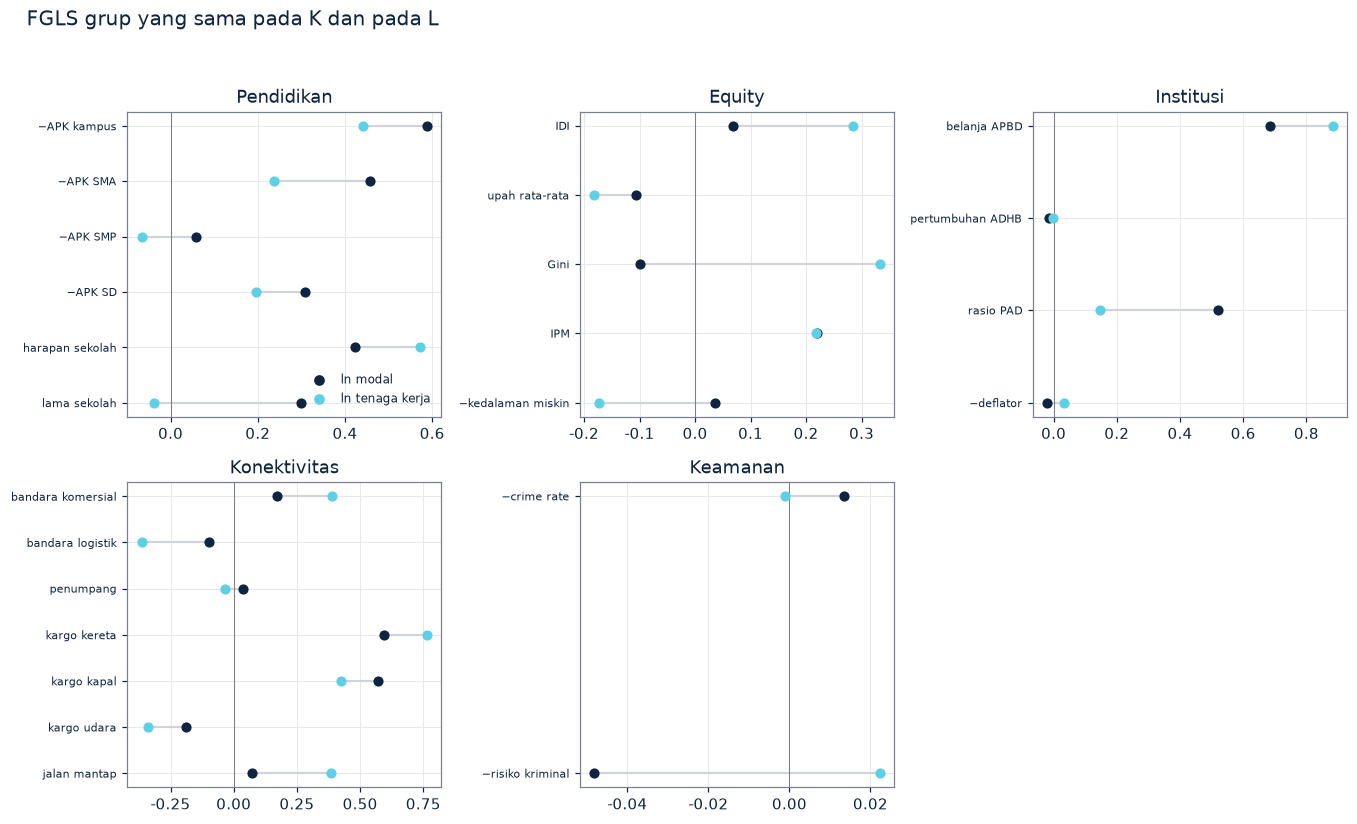

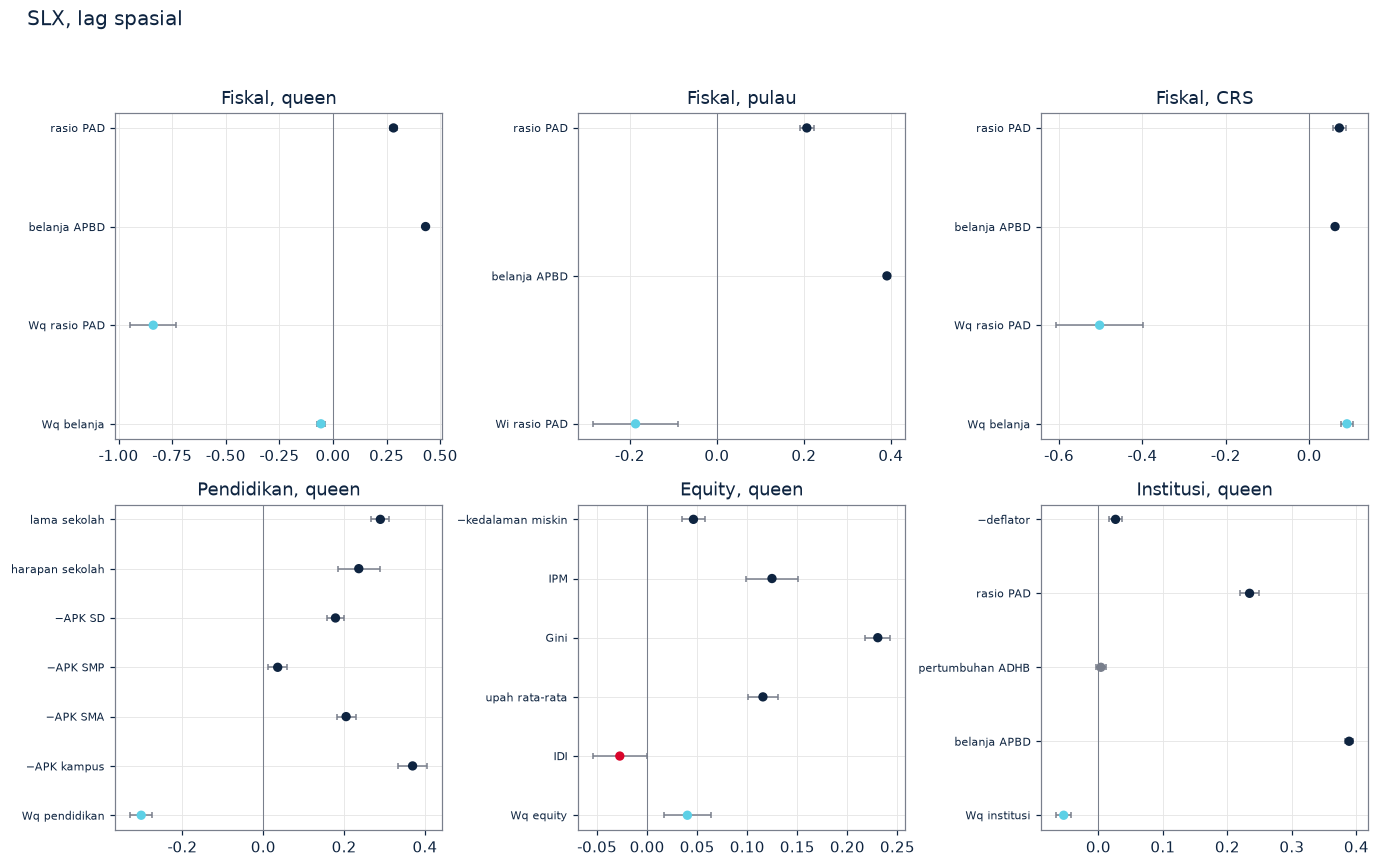

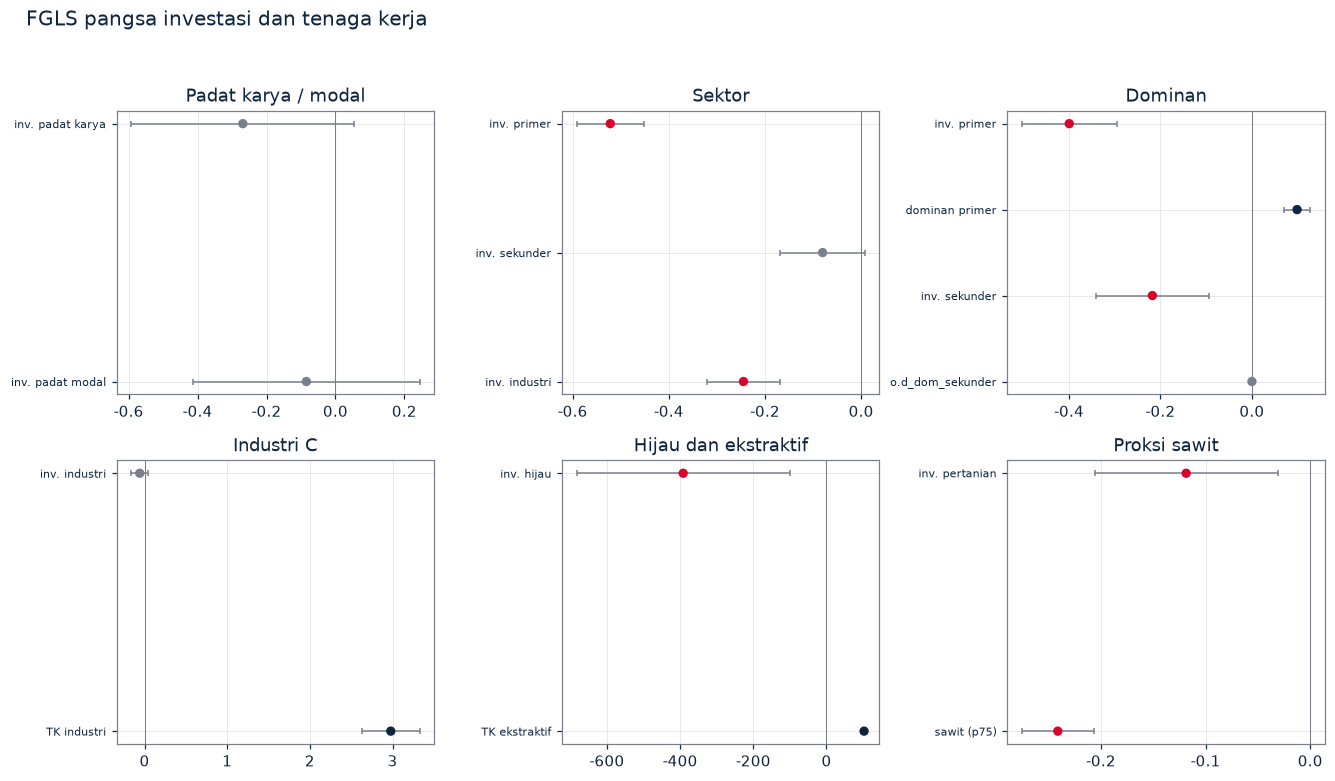

In [4]:
grup = ["pendidikan", "equity", "institusi", "konektivitas", "keamanan"]
fig, axes = plt.subplots(2, 3, figsize=(12.4, 7.6))
for ax, g in zip(axes.ravel(), grup):
    k = coef[coef.model == f"FGLS_K_{g}"].set_index("var")
    l = coef[coef.model == f"FGLS_L_{g}"].set_index("var")
    vs = [v for v in k.index if v in l.index]
    y = np.arange(len(vs))
    ax.axvline(0, color=GRAY, lw=0.7)
    for i, v in enumerate(vs):
        ax.plot([k.loc[v, "b"], l.loc[v, "b"]], [i, i], color="#D0D3D8", lw=1.4, zorder=1)
        ax.scatter(k.loc[v, "b"], i, s=32, color=NAVY, zorder=3)
        ax.scatter(l.loc[v, "b"], i, s=32, color=CYAN, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([LAB.get(v, v) for v in vs], fontsize=7)
    ax.set_title(g.capitalize())
axes.ravel()[-1].axis("off")
axes[0, 0].scatter([], [], color=NAVY, label="ln modal")
axes[0, 0].scatter([], [], color=CYAN, label="ln tenaga kerja")
axes[0, 0].legend(fontsize=8)
fig.suptitle("FGLS grup yang sama pada K dan pada L", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev2_dumbbell_KL.png")

slx_models = [
    ("FGLS_SLX_fiskal_q", "Fiskal, queen"),
    ("FGLS_SLX_fiskal_i", "Fiskal, pulau"),
    ("FGLS_SLX_crs_fiskal", "Fiskal, CRS"),
    ("FGLS_SLX_pend_q", "Pendidikan, queen"),
    ("FGLS_SLX_eq_q", "Equity, queen"),
    ("FGLS_SLX_inst_q", "Institusi, queen"),
]
fig, axes = plt.subplots(2, 3, figsize=(12.6, 8.0))
for ax, (model, title) in zip(axes.ravel(), slx_models):
    sub = coef[coef.model == model].iloc[::-1]
    y = np.arange(len(sub))
    ax.axvline(0, color=GRAY, lw=0.7)
    ax.errorbar(sub["b"], y, xerr=1.96 * sub["se"], fmt="none", ecolor=GRAY, elinewidth=1, capsize=2)
    colors = []
    for v, b, p in zip(sub["var"], sub["b"], sub["p"]):
        if p >= 0.05:
            colors.append(GRAY)
        elif str(v).startswith("W"):
            colors.append(CYAN)
        elif b >= 0:
            colors.append(NAVY)
        else:
            colors.append(RED)
    ax.scatter(sub["b"], y, c=colors, s=26, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([LAB.get(v, v) for v in sub["var"]], fontsize=7)
    ax.set_title(title)
fig.suptitle("SLX, lag spasial", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev2_slx.png")

inv_models = [
    ("FGLS_inv_pk", "Padat karya / modal"),
    ("FGLS_inv_sektor", "Sektor"),
    ("FGLS_inv_dom", "Dominan"),
    ("FGLS_invC_tkC", "Industri C"),
    ("FGLS_hijinv", "Hijau dan ekstraktif"),
    ("FGLS_sawit", "Proksi sawit"),
]
fig, axes = plt.subplots(2, 3, figsize=(12.2, 7.2))
for ax, (model, title) in zip(axes.ravel(), inv_models):
    sub = coef[coef.model == model].iloc[::-1]
    y = np.arange(len(sub))
    ax.axvline(0, color=GRAY, lw=0.7)
    ax.errorbar(sub["b"], y, xerr=1.96 * sub["se"], fmt="none", ecolor=GRAY, elinewidth=1, capsize=2)
    colors = [NAVY if (b > 0 and p < 0.05) else RED if (b < 0 and p < 0.05) else GRAY
              for b, p in zip(sub["b"], sub["p"])]
    ax.scatter(sub["b"], y, c=colors, s=26, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([LAB.get(v, v) for v in sub["var"]], fontsize=7)
    ax.set_title(title)
fig.suptitle("FGLS pangsa investasi dan tenaga kerja", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev2_investasi.png")
